# Notebook to help me organize my thoughts for designing an experimental protocol

Want to test the effects of different housing conditions on longevity for adult Ae. aegypti mosquitoes reared gnotobiotically with only E. coli. The three housing conditions are:
    1. Individually housed in tubes (IT)
    2. Individually housed in cups (IC)
    3. Group-housed in cups (GC)
We determine longevity by noting their date of pupation and then noting their date of death, checking the adults daily.

The larvae are raised in groups of 20 in individual sterile flasks. We want to apportion the pupae from these flasks in a way that doesn't introduce confounds wrt which flask they came from (flask_num) but also preserves the age of mosquitoes in our housing treatment groups (we want all of the mosquitoes in the group treatment to start at the same age so we have accurate longevity info). We lose flask info for the group-housed mosquitoes as we lose their identity, so maybe it's most important to think about experimental design for the individual cases.

**Let's start with 10 flasks. That gives us a good chance of getting >=2 good days, and just 1 good day might feel like a waste after all that work**

## To do
* Switch to looking at eclosion + pupation time rather than just pupation
* Will want to run each replicate with its own eggs, so I may need fewer days with >15 pupae

## Imports

In [3]:
import os
import pathlib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

## Load data from Luis's experiment

In [4]:
# path to Luis's data
path = pathlib.Path('C:\\Users\\samcw\\Dropbox\\Research_Scientist\\longevity_experiment')
filename = pathlib.Path('luis_data_development_times.csv')

In [5]:
# load data
dev_times_df = pd.read_csv(path / filename)
dev_times_df

,ID,community_fullname,community,PT,ET,wing_length,flask,type,Experiment,Source,Region
0,1,MX1,MX1,8,48,2.198,A,control,1,Polystyrene,LAB
1,2,MX1,MX1,8,48,2.187,A,control,1,Polystyrene,LAB
2,3,MX1,MX1,8,48,2.147,B,control,1,Polystyrene,LAB
3,4,MX1,MX1,9,48,2.058,A,control,1,Polystyrene,LAB
4,5,MX1,MX1,9,55,NaN,A,control,1,Polystyrene,LAB
...,...,...,...,...,...,...,...,...,...,...,...
636,637,MN5-A,25,9,48,2.132,A,treatment,3,Plastic,East
637,638,MN5-A,25,9,48,2.065,A,treatment,3,Plastic,East
638,639,MN5-A,25,9,31,2.158,A,treatment,3,Plastic,East
639,640,MN5-A,25,9,31,2.226,C,treatment,3,Plastic,East


In [6]:
# get just the monoxenic data
mx_idx = dev_times_df['community'].str.contains('MX')
mx_dev_times_df = dev_times_df[mx_idx].reset_index(drop=True)

# switch to multi-indexing so we can easily separate by replicate number
mx_dev_times_df.set_index(['community', 'ID'], inplace=True)

mx_dev_times_df

community_fullname  PT  ET  wing_length flask     type  \
community ID                                                           
MX1       1                  MX1   8  48        2.198     A  control   
          2                  MX1   8  48        2.187     A  control   
          3                  MX1   8  48        2.147     B  control   
          4                  MX1   9  48        2.058     A  control   
          5                  MX1   9  55          NaN     A  control   
...                          ...  ..  ..          ...   ...      ...   
MX3       412                MX3  16  48        1.624     A  control   
          413                MX3  18  31        1.644     A  control   
          414                MX3  18  48        1.648     A  control   
          415                MX3  18  48        1.721     A  control   
          416                MX3  20  31          NaN     A  control   

               Experiment       Source Region  
community ID                                   
MX1       1             1  Polystyrene    LAB  
          2             1  Polystyrene    LAB  
          3             1  Polystyrene    LAB  
          4             1  Polystyrene    LAB  
          5             1  Polystyrene    LAB  
...                   ...          ...    ...  
MX3       412           3  Polystyrene    LAB  
          413           3  Polystyrene    LAB  
          414           3  Polystyrene    LAB  
          415           3  Polystyrene    LAB  
          416           3  Polystyrene    LAB  

[78 rows x 9 columns]

Text(0.5, 1.0, 'Pupation Time')

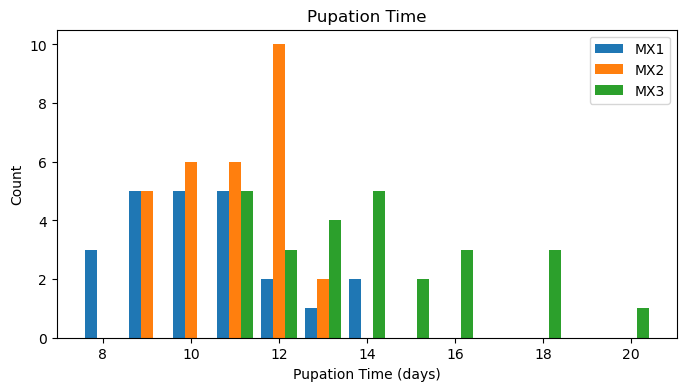

In [7]:
# plot the pupation time by each community
edges = np.arange(8, 22) - 0.5 
replicate_names = mx_dev_times_df['community_fullname'].unique()

# initialize figure 
fig, ax = plt.subplots(figsize=(8,4))

data_list = []
# loop over replicates
for name in replicate_names:
    data_curr = mx_dev_times_df.loc[(name, slice(None))]
    data_list.append(list(data_curr['PT'].values))
    # ax.hist(data_curr['PT'], bins=edges, alpha=0.2, label=name, edgecolor='k')

ax.hist(data_list, bins=edges, label=replicate_names)
ax.legend()
ax.set_xlabel('Pupation Time (days)')
ax.set_ylabel('Count')
ax.set_title('Pupation Time')

Text(0.5, 1.0, 'Eclosion Time')

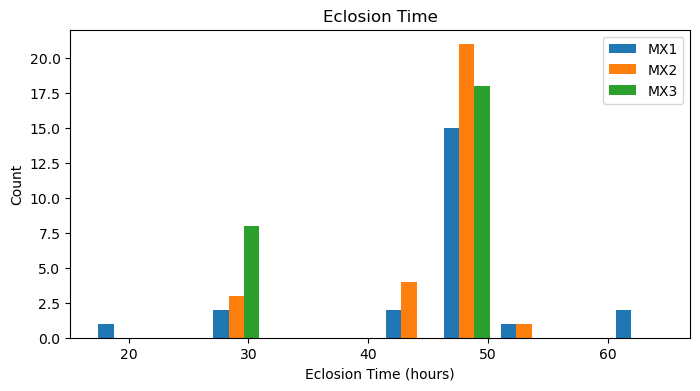

In [8]:
# plot the eclosion time by each community
# edges = np.arange(16, 64, 12) - 6 
replicate_names = mx_dev_times_df['community_fullname'].unique()

# initialize figure 
fig, ax = plt.subplots(figsize=(8,4))

data_list = []
# loop over replicates
for name in replicate_names:
    data_curr = mx_dev_times_df.loc[(name, slice(None))]
    data_list.append(list(data_curr['ET'].values))
    # ax.hist(data_curr['PT'], bins=edges, alpha=0.2, label=name, edgecolor='k')

ax.hist(data_list, label=replicate_names)
ax.legend()
ax.set_xlabel('Eclosion Time (hours)')
ax.set_ylabel('Count')
ax.set_title('Eclosion Time')

In [9]:
# define some arrays we can use for output
pupation_times_luis = mx_dev_times_df['PT'].values
pupation_times_luis_by_flask = []
for name in replicate_names:
    data_curr = mx_dev_times_df.loc[(name, slice(None))]
    pupation_times_luis_by_flask.append(list(data_curr['PT'].values))
# pupation_times_luis

## Try to get some guesses as to what our experiment might look like

In [10]:
def simulate_flask(pupation_times_in, n_larvae=20, male_probability=0.5):
    """
    Function to simulate the output of male mosquitoes and their pupation time for a single flask

    Args:
        pupation_times_in: a list of measured pupation times, in days
        n_larvae: the number of larvae per flask
        male_probability: the probability that an individual larva is a male

    Returns:
        pupation_times_out: a list of length N giving an estimate of the pupation times we'd observe, 
            where N is the estimated number of males
    """
    # first determine the breakdown of males vs females using binomial distribution
    n_males = np.random.binomial(n_larvae, male_probability)

    # then, for each male, estimate the pupation time
    pupation_times_out = np.random.choice(pupation_times_in, size=n_males, replace=True)

    return np.sort(pupation_times_out)
        

In [11]:
def simulate_experiment(pupation_times_by_flask, n_flasks=12, n_larvae=20, male_probability=0.5):
    """
    Function to simulate the yield from an experimental run by simulating multiple flasks

    Args:
        pupation_times_by_flask: a list of arrays, where each list entry is an array of measured pupation times from a given flask
        n_flasks: the number of flasks used in the experiment
        n_larvae: the number of larvae per flask
        male_probability: the probability that an individual larva is a male

    Returns:
        pupation_times_expt: a list of length n_flasks where each entry is an array containing estimated pupation times for that flask
    """
    # figure out the pupation time distribution to draw from
    sim_flask_nums = np.random.randint(0, high=len(pupation_times_by_flask), size=(n_flasks,))

    # initialize output
    pupation_times_expt = []
    
    # loop over flasks
    for sim_flask in sim_flask_nums:
        pup_times = simulate_flask(pupation_times_by_flask[sim_flask],
                                   n_larvae=n_larvae, 
                                   male_probability=male_probability)
        pupation_times_expt.append(pup_times)

    return pupation_times_expt
        

In [12]:
def check_expt_sim(pupation_times_sim, n_pupae_target=15):
    """
    Want to know how many flasks we would need to start with to have a few days where we get >=15 pupae across all flasks
    """
    # make sure experiment data is in the form we want
    if pupation_times_sim is not list: 
        pupation_times_sim = np.hstack(pupation_times_sim)

    # get count of days above target number of pupae
    _, day_counts = np.unique(pupation_times_sim, return_counts=True)

    # return the number of days we get above threshold pupae count
    return np.sum(day_counts >= n_pupae_target)
    

In [19]:
# run simulations many times to see how often we hit the desired number of pupae per day for a given flask number
# define parameters
n_flasks = 10 # number of flasks
n_larvae = 20  # number of larvae in each flask
n_pupae_target = 15  # number of pupae we would like to see per day
male_probability=0.5  # probability that a mosquito larva will be male
n_sim = 1000  # number of times to run our simulation

# run sim
sim_out = []
for _ in range(n_sim):
    # run simulation
    pup_times_sim = simulate_experiment(pupation_times_luis_by_flask,
                                        n_flasks=n_flasks,
                                        n_larvae=n_larvae,
                                        male_probability=male_probability)

    # check output
    good_day_count = check_expt_sim(pup_times_sim, n_pupae_target=n_pupae_target)

    # store
    sim_out.append(good_day_count)
    

Text(0.5, 1.0, '10 flasks')

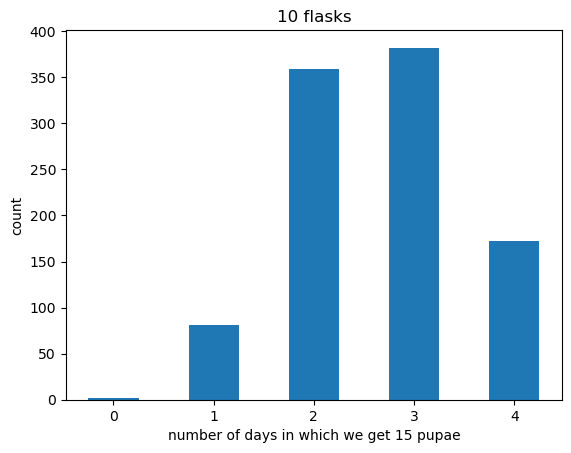

In [20]:
# plot the distribution of "good days"
fig, ax = plt.subplots()

bins = np.arange(-0.5, max(sim_out) + 0.5)
ax.hist(sim_out, bins=bins, rwidth=0.5)

ax.set_xlabel(f'number of days in which we get {n_pupae_target} pupae')
ax.set_ylabel('count')
ax.set_title(f'{n_flasks} flasks')